### Import Libraries

In [3]:
import tensorflow as tf
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Import DataSet

In [4]:
temp_df = pd.read_csv("temperature_data.csv")
temp_df.head(5)

,Celsius,Fahrenheit
0,-50,-58.0
1,-40,-40.0
2,-30,-22.0
3,-20,-4.0
4,-10,14.0


In [5]:
temp_df.tail(5)

,Celsius,Fahrenheit
25,20,68.0
26,30,86.0
27,40,104.0
28,50,122.0
29,60,140.0


In [4]:
temp_df.describe()

,Celsius,Fahrenheit
count,30.000000,30.000000
mean,2.000000,35.600000
std,22.780815,41.005466
min,-50.000000,-58.000000
25%,-6.750000,19.850000
50%,0.500000,32.900000
75%,7.750000,45.950000
max,60.000000,140.000000


In [6]:
temp_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Celsius     30 non-null     int64  
 1   Fahrenheit  30 non-null     float64
dtypes: float64(1), int64(1)
memory usage: 612.0 bytes


### STEP # 2 : VISUALIZE DATASET

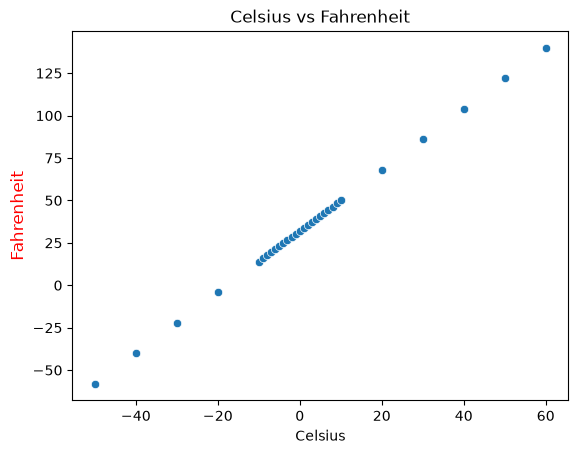

In [6]:
ax = sns.scatterplot(data=temp_df, x='Celsius', y='Fahrenheit')
ax.set_xlabel('Celsius')
ax.set_ylabel('Fahrenheit', fontsize=12, color='Red')
ax.set_title('Celsius vs Fahrenheit')
plt.show()

### STEP 3 : CREATE TESTING AND TRAINING DATASET

In [7]:
x_train = temp_df[['Celsius']]
y_train = temp_df[['Fahrenheit']]

### SETP 4 : BUILD AND TRAIN THE MODEL

In [8]:
x_train.shape

(30, 1)

In [9]:
y_train.shape

(30, 1)

In [9]:
model = tf.keras.Sequential()
model.add(tf.keras.layers.Dense(units=1, input_shape=[1]))

c:\ML\.venv\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [10]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2 (8.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 0 (0.00 B)

In [11]:
model.compile(optimizer=tf.keras.optimizers.Adam(0.5), loss='mean_squared_error')

In [12]:
epoocs_host = model.fit(x_train, y_train, epochs=120)

Epoch 1/120
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 367ms/step - loss: 5146.4917
Epoch 2/120
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - loss: 3791.4695
Epoch 3/120
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - loss: 2700.8347
Epoch 4/120
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - loss: 1874.2479
Epoch 5/120
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - loss: 1303.4767
Epoch 6/120
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - loss: 968.9305
Epoch 7/120
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - loss: 836.5469
Epoch 8/120
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - loss: 856.9756
Epoch 9/120
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - loss: 969.6375
Epoch 10/120
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - loss: 1112.3982
Epoch 11/120
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - loss: 1233.5343
Epoch 12/120
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - loss: 1300.2340
Epoch 13/120
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - loss: 1300.3207
Epoch 14/120
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - loss: 1238.3962
Epoch 15/120
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/

In [13]:
epoocs_host.history.keys()


dict_keys(['loss'])

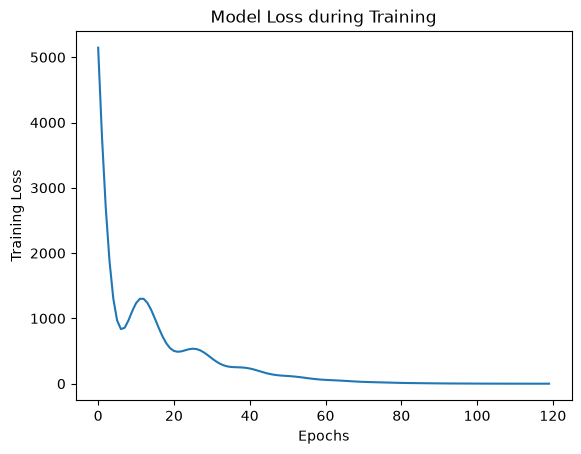

In [14]:
plt.plot(epoocs_host.history['loss'])
plt.title('Model Loss during Training')
plt.xlabel('Epochs')
plt.ylabel('Training Loss')
plt.show()

In [15]:
model.get_weights()

[array([[1.7986012]], dtype=float32), array([31.679811], dtype=float32)]

ANN - Artificial Nural Network

In [18]:
temp_c = 25

Temp_F = model.predict(np.array([[temp_c]], dtype=np.float32))
print(f"{temp_c}°C is equal to {Temp_F}°F")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
25°C is equal to [[76.64484]]°F


In [19]:
Temp_F = 9/5 * temp_c + 32
print("Temprature in DegF using Equation-", Temp_F)

Temprature in DegF using Equation- 77.0
